# Ottimizzazione delle prestazioni di una rete neurale per il settore food
GourmetAI Inc., una rinomata azienda nel settore della tecnologia alimentare, si trova ad affrontare sfide crescenti nel migliorare l'accuratezza e l'efficienza dei sistemi di classificazione delle immagini di cibo. La necessità di fornire ai clienti soluzioni avanzate e di alta qualità per identificare e categorizzare correttamente i cibi è essenziale per migliorare l'esperienza utente e ottimizzare i processi aziendali.

**Benefici del Progetto**: L'implementazione di tecniche avanzate di deep learning per la classificazione delle immagini di cibo offre numerosi vantaggi:

- **Miglioramento dell'Esperienza Utente**: Un sistema preciso e affidabile migliora significativamente l'esperienza degli utenti nelle applicazioni di riconoscimento di immagini di cibo, fornendo risultati rapidi e accurati.
- **Ottimizzazione dei Processi Aziendali**: Automatizzare la classificazione delle immagini riduce il tempo e le risorse necessarie per identificare e categorizzare i cibi, migliorando l'efficienza operativa complessiva.
- **Innovazione Tecnologica**: Utilizzare tecniche avanzate di deep learning promuove l'innovazione all'interno dell'azienda, consentendo di affrontare sfide complesse nel settore del riconoscimento delle immagini.
- **Obiettivi di Business**: Migliorare le performance dei modelli di classificazione aiuta GourmetAI Inc. a soddisfare gli obiettivi di business, consolidando la propria posizione come leader nel settore della tecnologia alimentare.

**Dettagli del Progetto**: GourmetAI Inc. ha richiesto lo sviluppo di un modello avanzato di classificazione di immagini di cibo utilizzando tecniche di deep learning. Il progetto si baserà sul dataset Food Classification, arricchito con tecniche di augmentation per migliorare la diversità e la qualità dei dati disponibili.

**Obiettivi del Progetto**:

- **Strategie di Augmentation**: Implementare diverse tecniche di augmentation per arricchire il dataset, migliorando la variabilità e la qualità dei dati.
- **Divisione del Dataset**: Suddividere il dataset in trainset, valset e testset per garantire un'adeguata formazione e validazione del modello.
- **Architetture di Rete e Transfer Learning**: Selezionare e implementare una o più architetture di rete neurale adatte al problema, utilizzando il transfer learning per sfruttare modelli pre-addestrati.
- **Fine Tuning e Scelta degli Hyperparameters**: Creare un classificatore personalizzato, scegliere gli hyperparameters e ottimizzare il modello attraverso processi di training e validation.
- **Validation e Regolarizzazione**: Utilizzare tecniche di validation per migliorare la scelta degli hyperparameters e risolvere potenziali problemi con tecniche di regolarizzazione.
- **Test Finale**: Eseguire un test finale per verificare le capacità di generalizzazione del modello e raggiungere le performance desiderate.

**Fasi del Progetto**:

- **Sviluppo delle Strategie di Augmentation**: Esplorazione e implementazione di tecniche di augmentation per arricchire il dataset.
- **Preparazione del Dataset**: Divisione del dataset in trainset, valset e testset; preparazione degli strumenti per l'utilizzo delle immagini come input.
- **Selezione e Implementazione delle Architetture**: Scelta e implementazione di architetture di rete neurale, applicando il transfer learning.
- **Fine Tuning e Scelta degli Hyperparameters**: Creazione di un classificatore personalizzato, selezione degli hyperparameters e ottimizzazione del modello.
- **Validation e Regolarizzazione**: Ripetizione del training con tecniche di validation e regolarizzazione per migliorare le performance del modello.
- **Test Finale**: Esecuzione di un test finale per valutare le capacità di generalizzazione del modello e confrontare i risultati con le aspettative.

**Motivazione del Progetto**: Per GourmetAI Inc., la precisione nella classificazione delle immagini di cibo rappresenta un requisito fondamentale. Migliorare l'efficacia dei sistemi di classificazione non solo migliora l'esperienza utente e ottimizza i processi aziendali, ma consente anche di consolidare la leadership nel settore della tecnologia alimentare attraverso l'innovazione tecnologica.

Con questo progetto, GourmetAI Inc. mira a sviluppare e implementare un sistema avanzato di classificazione di immagini di cibo, utilizzando tecniche all'avanguardia di deep learning per raggiungere performance superiori e soddisfare le esigenze specifiche del mercato.

**Dataset**: Il dataset è disponibile al seguente link: https://proai-datasets.s3.eu-west-3.amazonaws.com/dataset_food_classification.zip

## Imports

Importiamo le librerie necessarie: `torch`/`torchvision` per la costruzione e il training della rete, `matplotlib`/`seaborn` per le visualizzazioni, `sklearn.metrics` per le metriche di valutazione e `tqdm` per le progress bar durante il training.

In [1]:
import os
import random
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader
from torchvision.models import vgg19, VGG19_Weights, resnet152, ResNet152_Weights
from torchvision.transforms import functional as TF
from torchsummary import summary
from tqdm.auto import tqdm
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
# Hyperparameters
batch_size = 32
epochs = 50
lr = 1e-3
seed = 42

torch.manual_seed(seed)
random.seed(seed)
os.environ['PYTHONHASHSEED'] = str(seed)
np.random.seed(seed)

## Utils functions

- `back_to_image`: Converte un tensore normalizzato in un'immagine visualizzabile.
- `load_log`: Carica un file JSON contenente i log di addestramento e
- `plot_models_comparison`: Confronta più modelli mostrando in un grafico la perdita di addestramento e di validazione, e in un secondo grafico l'accuratezza di validazione.
- `plot_confusion_matrix`: Calcola le predizioni del modello sul test set e mostra la matrice di confusione (normalizzata o assoluta), restituendo le etichette vere e predette.

In [3]:
def back_to_image(img):
    img = img / 2 + 0.5
    np_img = img.numpy()
    return np.transpose(np_img, (1, 2, 0))


def load_log(log_path):
    with open(log_path, 'r') as f:
        return json.load(f)


def plot_models_comparison(logs, figsize=(14, 5)):
    """
    Confronta piu' modelli mostrando in un grafico train loss + validation loss
    (insieme, una linea tratteggiata per la validation) e in un secondo grafico
    la validation accuracy.

    Parameters
    ----------
    logs : dict[str, str]
        Dizionario {nome_modello: path_al_log_json}.
    """
    fig, axes = plt.subplots(1, 2, figsize=figsize)
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

    for i, (name, log_path) in enumerate(logs.items()):
        data = load_log(log_path)
        epochs_range = range(1, len(data["train_losses"]) + 1)
        color = colors[i % len(colors)]

        axes[0].plot(epochs_range, data["train_losses"], label=f"{name} (train)",
                     color=color, linestyle='-', marker='o', markersize=3)
        axes[0].plot(epochs_range, data["test_losses"], label=f"{name} (val)",
                     color=color, linestyle='--', marker='x', markersize=3)

        axes[1].plot(epochs_range, data["test_accuracies"], label=name, color=color, marker='o', markersize=3)

    axes[0].set_title("Train Loss vs Validation Loss")
    axes[0].set_ylabel("Loss")

    axes[1].set_title("Validation Accuracy")
    axes[1].set_ylabel("Accuracy")

    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(True, alpha=0.3)
        ax.legend()

    plt.tight_layout()
    plt.show()

def plot_confusion_matrix(model, classes, test_loader, device, normalize=True):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for i, data in enumerate(test_loader, 0):
            inputs, labels = data[0].to(device), data[1].to(device)

            outputs = model(inputs)

            _, predicted = torch.max(outputs, 1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    cm = confusion_matrix(y_true, y_pred, normalize='true' if normalize else None)
    fmt = '.2f' if normalize else 'd'

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt=fmt, xticklabels=classes, yticklabels=classes, cmap='Blues')
    plt.title("Confusion Matrix" + (" (normalizzata per riga)" if normalize else ""))
    plt.xlabel("Predetta")
    plt.ylabel("Reale")
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return y_true, y_pred

## Dataset

Carichiamo il dataset e applichiamo le trasformazioni necessarie per l'addestramento e la validazione. Utilizziamo tecniche di augmentation per migliorare la diversità dei dati di addestramento.

In [4]:
class RandomRotate90:
    """Rotate the image by a random multiple of 90 degrees."""

    def __call__(self, img):
        angle = random.choice([0, 90, 180, 270])
        return TF.rotate(img, angle)


transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

augment = transforms.Compose([
    transforms.Resize((256, 256)),
    RandomRotate90(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomApply([
        transforms.RandomChoice([
            transforms.RandomAffine(degrees=0, shear=20),
            transforms.RandomAffine(degrees=0, scale=(1.2, 1.2)),
        ])
    ], p=0.6),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

#carica i dataset
train_set = torchvision.datasets.ImageFolder(root='dataset/train', transform=augment)
val_set = torchvision.datasets.ImageFolder(root='dataset/val', transform=transform)
test_set = torchvision.datasets.ImageFolder(root='dataset/test', transform=transform)

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=0,
                          pin_memory=(device.type == "cuda"), drop_last=True)
val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False, num_workers=0,
                        pin_memory=(device.type == "cuda"))
test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=0,
                         pin_memory=(device.type == "cuda"))

print(f"Train set: {len(train_set)} immagini, {len(train_set.classes)} classi")
print(f"Val set:   {len(val_set)} immagini")
print(f"Test set:  {len(test_set)} immagini")

Train set: 8960 immagini, 14 classi
Val set:   2240 immagini
Test set:  2800 immagini


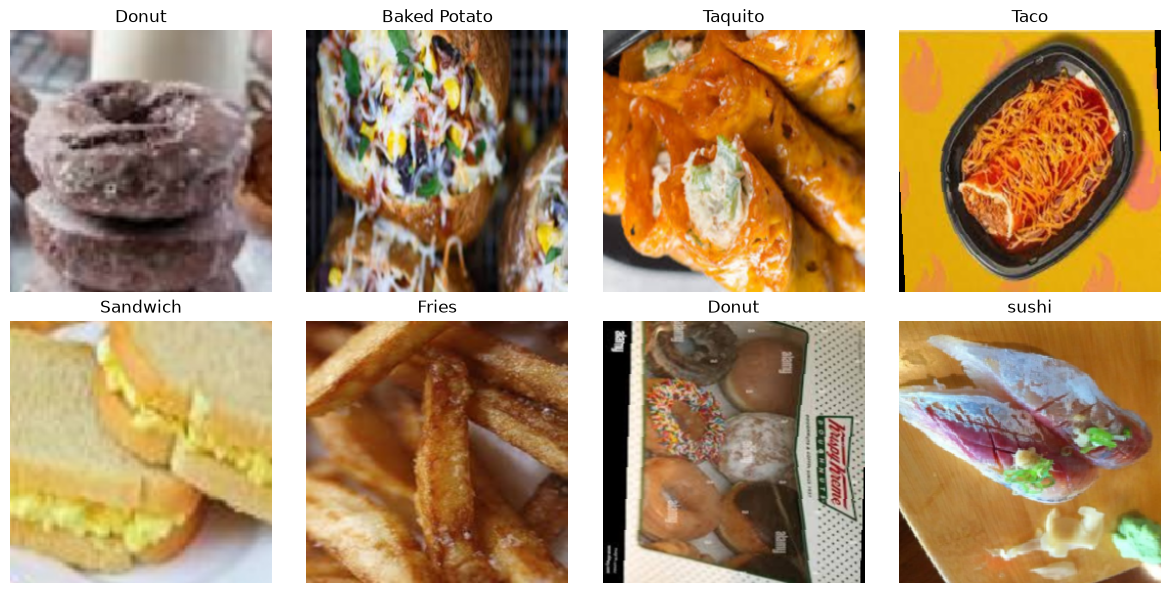

In [5]:
def show_images(dataset, n=8, cols=4):
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
    axes = axes.flatten()

    indices = random.sample(range(len(dataset)), n)
    for ax, idx in zip(axes, indices):
        img, label = dataset[idx]
        img = back_to_image(img.clamp(-1, 1))

        ax.imshow(img)
        ax.set_title(dataset.classes[label])
        ax.axis('off')

    for ax in axes[len(indices):]:
        ax.axis('off')

    plt.tight_layout()
    plt.show()


show_images(train_set, n=8)

## Train methods

- `EarlyStopping`: Interrompe l'addestramento quando la validation loss non migliora per un numero di epoche pari a `patience`, salvando su disco i pesi del modello migliore (checkpoint).
- `train_epoch`: Esegue un'epoca di addestramento (forward, calcolo della loss, backward e aggiornamento dei pesi) e restituisce la train loss media.
- `test_epoch`: Valuta il modello su un dataloader (validation o test) senza aggiornare i pesi, restituendo loss media e accuratezza.
- `train`: Ciclo di addestramento completo che alterna `train_epoch` e `test_epoch` per il numero di epoche richiesto, applicando l'early stopping se fornito.

In [6]:
class EarlyStopping:
    def __init__(self, save_path, patience=5, min_delta=0):

        self.save_path = save_path
        self.patience = patience
        self.min_delta = min_delta
        self.min_val_loss = None
        self.counter = 0
        self.early_stop = False

    def __call__(self, validation_loss, model):

        if self.min_val_loss is None:  #Prima epoca
            self.min_val_loss = validation_loss
            self.save_checkpoint(model)

        elif (self.min_val_loss - validation_loss) > self.min_delta:  #Epoca con miglioramento
            self.min_val_loss = validation_loss
            self.save_checkpoint(model)
            self.counter = 0

        else:  #Nessun miglioramento
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

    def save_checkpoint(self, model):
        torch.save(model.state_dict(), self.save_path)

In [7]:
def train_epoch(model, train_loader, criterion, optimizer, device, epoch, epochs):
    model.train()
    running_loss = 0.0

    lr = optimizer.param_groups[0]['lr']
    batch_size = train_loader.batch_size

    tq = tqdm(total=len(train_loader) * batch_size)
    tq.set_description('epoch %d/%d, lr %f' % (epoch, epochs, lr))

    for i, (data, label) in enumerate(train_loader):
        data = data.to(device)  #[128, 256, 256]
        label = label.to(device)  # [128, 14]
        optimizer.zero_grad()

        outputs = model(data)  #[128, 14]
        loss = criterion(outputs, label)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        tq.update(batch_size)
        tq.set_postfix(loss='%.4f' % loss.item())

    tq.close()
    return running_loss / len(train_loader)


def test_epoch(model, test_loader, criterion, device, epoch=0, epochs=1):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    tq = tqdm(total=len(test_loader.dataset))
    tq.set_description('epoch %d/%d, validation' % (epoch, epochs))

    with torch.no_grad():
        for i, (data, label) in enumerate(test_loader):
            data = data.to(device)
            label = label.to(device)

            outputs = model(data)
            loss = criterion(outputs, label)

            # val/test_loader non ha drop_last=True (non vogliamo scartare campioni di valutazione),
            # quindi l'ultimo batch puo' avere dimensione diversa dagli altri: per una media ESATTA
            # per campione, de-mediamo la loss del batch moltiplicando per la sua dimensione.
            running_loss += loss.item() * data.size(0)

            _, predicted = torch.max(outputs, 1)
            correct += (predicted == label).sum().item()
            total += label.size(0)

            tq.update(data.size(0))
            tq.set_postfix(loss='%.4f' % loss.item())

    tq.close()
    return running_loss / total, correct / total


def train(model, train_loader, test_loader, criterion, optimizer, device, epochs=100, early_stopping=None):
    train_losses = []
    test_losses = []
    test_accuracies = []

    for epoch in range(epochs):
        train_loss = train_epoch(model, train_loader, criterion, optimizer, device, epoch, epochs)
        test_loss, test_accuracy = test_epoch(model, test_loader, criterion, device, epoch, epochs)

        train_losses.append(train_loss)
        test_losses.append(test_loss)
        test_accuracies.append(test_accuracy)

        print(
            f'Epoch {epoch + 1}/{epochs}, Train Loss: {train_loss:.4f}, Validation Loss: {test_loss:.4f}, Validation Accuracy: {test_accuracy:.4f}')

        if early_stopping is not None:
            early_stopping(test_loss, model)
            if early_stopping.early_stop:
                print("Early stopping")
                break

    return train_losses, test_losses, test_accuracies

## Models

1. **VGG19**: Una rete neurale convoluzionale profonda con 19 strati, nota per la sua architettura semplice e efficace.
2. **ResNet152**: Una rete neurale convoluzionale profonda con 152 strati, caratterizzata dall'uso di blocchi residui che facilitano l'addestramento di reti molto profonde.

In [8]:
class VGGClassifier(nn.Module):
    def __init__(self, vgg_backbone, in_features, num_classes):
        super().__init__()
        self.features = vgg_backbone.features
        self.pooling = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(in_features, num_classes)

    def forward(self, x):
        x = self.features(x)  #[N, 512, 8, 8]
        x = self.pooling(x)  #[N, 512, 1, 1]
        x = torch.flatten(x, 1)  #[N, 512]
        x = self.fc(x)  #[N, 14]
        return x


vgg = vgg19(weights=VGG19_Weights.IMAGENET1K_V1).to(device)

# freeze
for param in vgg.parameters():
    param.requires_grad = False

vgg = VGGClassifier(vgg, 512, 14).to(device)
summary(vgg, (3, 256, 256))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 256, 256]           1,792
              ReLU-2         [-1, 64, 256, 256]               0
            Conv2d-3         [-1, 64, 256, 256]          36,928
              ReLU-4         [-1, 64, 256, 256]               0
         MaxPool2d-5         [-1, 64, 128, 128]               0
            Conv2d-6        [-1, 128, 128, 128]          73,856
              ReLU-7        [-1, 128, 128, 128]               0
            Conv2d-8        [-1, 128, 128, 128]         147,584
              ReLU-9        [-1, 128, 128, 128]               0
        MaxPool2d-10          [-1, 128, 64, 64]               0
           Conv2d-11          [-1, 256, 64, 64]         295,168
             ReLU-12          [-1, 256, 64, 64]               0
           Conv2d-13          [-1, 256, 64, 64]         590,080
             ReLU-14          [-1, 256,

In [9]:
class ResNetClassifier(nn.Module):
    def __init__(self, resnet_backbone, in_features, num_classes):
        super().__init__()
        self.features = nn.Sequential(*list(resnet_backbone.children())[:-2])
        self.pooling = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(in_features, num_classes)

    def forward(self, x):
        x = self.features(x)  #[N, 2048, 8, 8]
        x = self.pooling(x)  #[N, 2048, 1, 1]
        x = torch.flatten(x, 1)  #[N, 2048]
        x = self.fc(x)  #[N, 14]
        return x


ResNet = resnet152(weights=ResNet152_Weights.IMAGENET1K_V2).to(device)
for param in ResNet.parameters():
    param.requires_grad = False

ResNet = ResNetClassifier(ResNet, 2048, 14).to(device)
summary(ResNet, (3, 256, 256))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 128, 128]           9,408
       BatchNorm2d-2         [-1, 64, 128, 128]             128
              ReLU-3         [-1, 64, 128, 128]               0
         MaxPool2d-4           [-1, 64, 64, 64]               0
            Conv2d-5           [-1, 64, 64, 64]           4,096
       BatchNorm2d-6           [-1, 64, 64, 64]             128
              ReLU-7           [-1, 64, 64, 64]               0
            Conv2d-8           [-1, 64, 64, 64]          36,864
       BatchNorm2d-9           [-1, 64, 64, 64]             128
             ReLU-10           [-1, 64, 64, 64]               0
           Conv2d-11          [-1, 256, 64, 64]          16,384
      BatchNorm2d-12          [-1, 256, 64, 64]             512
           Conv2d-13          [-1, 256, 64, 64]          16,384
      BatchNorm2d-14          [-1, 256,

## Training

Addestriamo entrambi i modelli (VGG19 e ResNet152) sullo stesso train/val set, usando l'`EarlyStopping` per salvare il checkpoint con la validation loss più bassa e i relativi log di training/validazione in formato JSON.

In [10]:
# settings

vgg_save_folder = "models/vgg/"
os.makedirs(vgg_save_folder, exist_ok=True)
vgg_save_file = os.path.join(vgg_save_folder, "model.pt")
vgg_save_log = os.path.join(vgg_save_folder, "log.json")
vgg_optimizer = torch.optim.Adam(vgg.parameters(), lr=lr)
vgg_early_stopping = EarlyStopping(vgg_save_file, patience=5, min_delta=0)

resnet_save_folder = "models/resnet/"
os.makedirs(resnet_save_folder, exist_ok=True)
resnet_save_file = os.path.join(resnet_save_folder, "model.pt")
resnet_save_log = os.path.join(resnet_save_folder, "log.json")
resnet_optimizer = torch.optim.Adam(ResNet.parameters(), lr=lr)
resnet_early_stopping = EarlyStopping(resnet_save_file, patience=5, min_delta=0)

loss = nn.CrossEntropyLoss()

In [ ]:
train_losses, test_losses, test_accuracies = train(vgg, train_loader, val_loader, loss, vgg_optimizer, device, epochs,
                                                   vgg_early_stopping)
to_save_json = {"train_losses": train_losses,
                "test_losses": test_losses,
                "test_accuracies": test_accuracies}
with open(vgg_save_log, 'w') as f:
    json.dump(to_save_json, f)

In [ ]:
train_losses, test_losses, test_accuracies = train(ResNet, train_loader, val_loader, loss, resnet_optimizer, device, epochs,
                                                   resnet_early_stopping)
to_save_json = {"train_losses": train_losses,
                "test_losses": test_losses,
                "test_accuracies": test_accuracies}
with open(resnet_save_log, 'w') as f:
    json.dump(to_save_json, f)

## Confronto dei modelli

Confrontiamo le curve di train/validation loss e la validation accuracy di VGG19 e ResNet152 per scegliere il modello con le performance migliori da valutare sul test set.

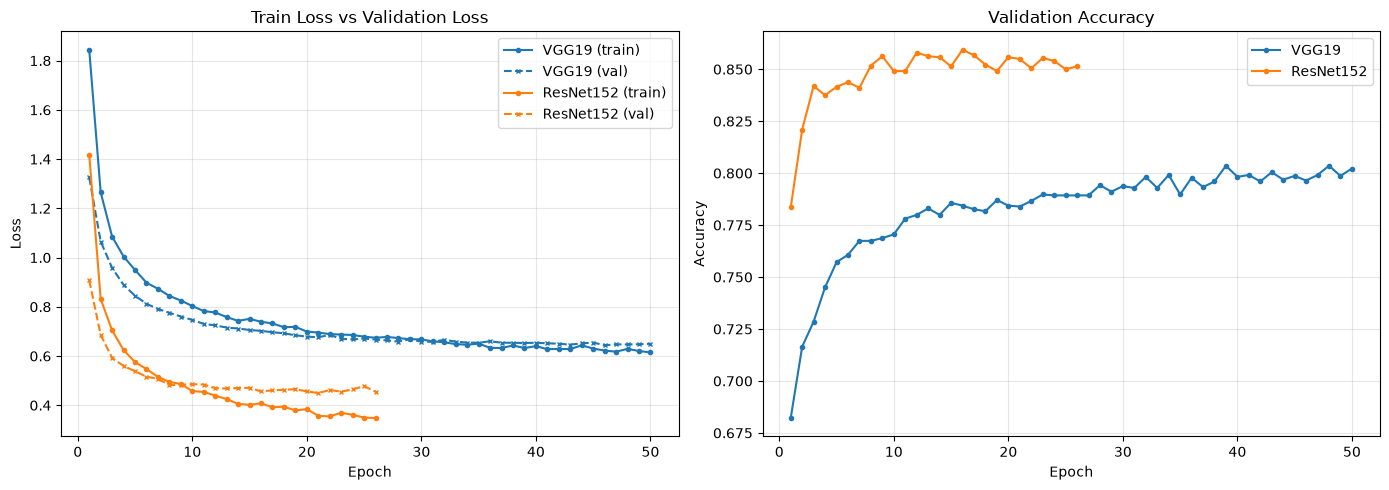

In [11]:
plot_models_comparison({
    "VGG19": vgg_save_log,
    "ResNet152": resnet_save_log,
})

## Test finale
Valutiamo il modello migliore (ResNet152) sul test set, utilizzando i pesi salvati dall'`EarlyStopping`
durante il training (checkpoint con la validation loss piu' bassa), per stimare la sua reale
capacita' di generalizzazione su dati mai visti ne' in training ne' in validation.

In [13]:
# Carica i pesi del miglior checkpoint salvato durante il training
ResNet.load_state_dict(torch.load(resnet_save_file, map_location=device))
ResNet.to(device)

test_loss, test_accuracy = test_epoch(ResNet, test_loader, loss, device)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

  0%|          | 0/2800 [00:00<?, ?it/s]

Test Loss: 0.4835
Test Accuracy: 0.8429


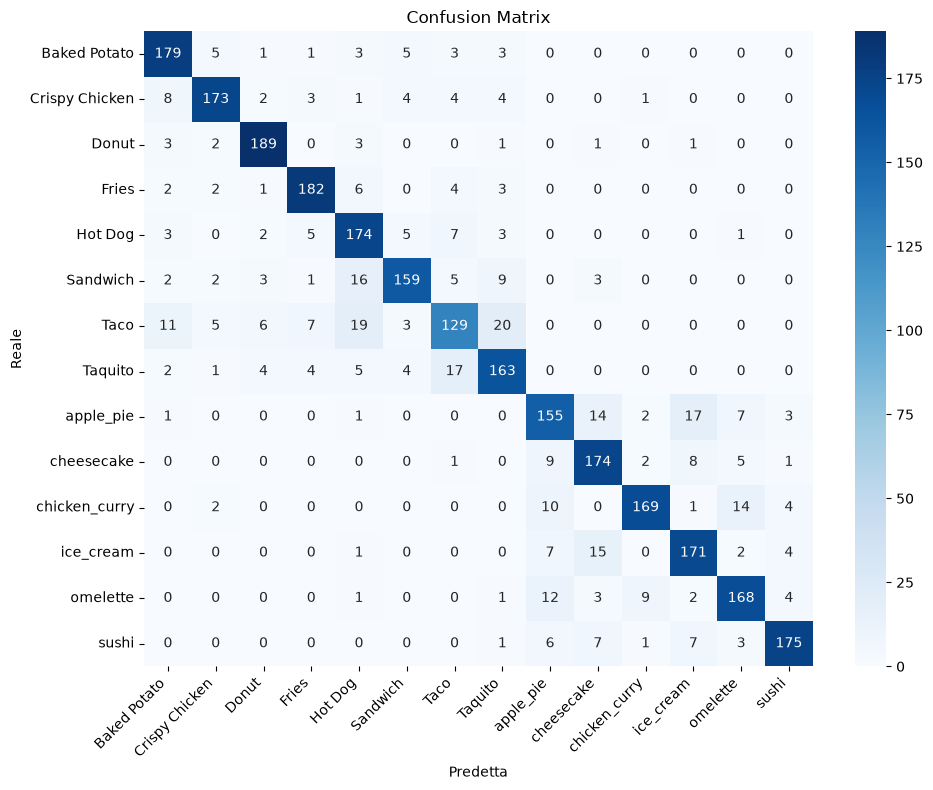

                precision    recall  f1-score   support

  Baked Potato       0.85      0.90      0.87       200
Crispy Chicken       0.90      0.86      0.88       200
         Donut       0.91      0.94      0.93       200
         Fries       0.90      0.91      0.90       200
       Hot Dog       0.76      0.87      0.81       200
      Sandwich       0.88      0.80      0.84       200
          Taco       0.76      0.65      0.70       200
       Taquito       0.78      0.81      0.80       200
     apple_pie       0.78      0.78      0.78       200
    cheesecake       0.80      0.87      0.83       200
 chicken_curry       0.92      0.84      0.88       200
     ice_cream       0.83      0.85      0.84       200
      omelette       0.84      0.84      0.84       200
         sushi       0.92      0.88      0.90       200

      accuracy                           0.84      2800
     macro avg       0.84      0.84      0.84      2800
  weighted avg       0.84      0.84      0.84 

In [19]:
y_true, y_pred = plot_confusion_matrix(ResNet, train_set.classes, test_loader, device, normalize=False)
print(classification_report(y_true, y_pred, target_names=train_set.classes))